# Offline RL com um dataset pronto do Minari: BC × DQN offline × CQL × IQL

**Benchmark:** `D4RL/minigrid/fourrooms-v0` e `D4RL/minigrid/fourrooms-random-v0`, os datasets de **ações discretas** da coleção D4RL hospedada no Minari.

**Pergunta:** com o mesmo dataset, a mesma rede e o mesmo orçamento de treino, como se comparam
- **BC**: imitação supervisionada;
- **DQN offline**: Q-learning "ingênuo" (Double DQN) sem nenhuma proteção contra ações fora da distribuição;
- **CQL**: Q-learning **pessimista**, que penaliza valores de ações não vistas;
- **IQL**: Q-learning **implícito**, que nunca consulta ações fora dos dados.

**Instalação (na sua máquina):**
```bash
pip install "minari[hf]" pyarrow minigrid torch matplotlib
```

O notebook roda em CPU. Com 2 núcleos leva cerca de 1 hora; com 8 núcleos, uns 15 minutos.

## 1. O ambiente e os datasets

**MiniGrid FourRooms** é um labirinto 19×19 com quatro salas ligadas por passagens estreitas. A posição inicial do agente e a do objetivo (quadrado verde) mudam a cada episódio.

- **Observação:** visão *egocêntrica parcial* de 7×7 células (tipo de objeto, cor e estado em cada uma) mais a direção do agente. O agente **não vê o mapa inteiro**: o problema é parcialmente observável.
- **Ações (7):** 0 = girar à esquerda, 1 = girar à direita, 2 = andar para frente, 3 = pegar, 4 = soltar, 5 = abrir/alternar, 6 = concluir. Em FourRooms, as ações 3 a 6 **não têm efeito**.
- **Recompensa:** esparsa, $1 - 0{,}9 \cdot \frac{\text{passos}}{100}$ ao chegar ao objetivo e 0 caso contrário. Episódios são truncados em 100 passos.

| Dataset | Política comportamental | Tamanho |
|---|---|---|
| `D4RL/minigrid/fourrooms-v0` | **especialista** com acesso ao mapa completo (busca em largura até o objetivo) | ~10 mil passos |
| `D4RL/minigrid/fourrooms-random-v0` | **aleatória** uniforme sobre as 7 ações | 1 milhão de passos |

Também vamos criar um terceiro cenário, **misto** = especialista + aleatório, que imita a situação comum na prática: poucos dados bons misturados com muitos dados ruins.

> **Nota sobre esta execução.** O servidor onde este notebook foi executado não tinha acesso ao Hugging Face, de onde o Minari baixa os datasets.
> Por isso os dois datasets foram regenerados localmente com o **script oficial** da Farama
> ([`minari-dataset-generation-scripts/scripts/D4RL/minigrid`](https://github.com/Farama-Foundation/minari-dataset-generation-scripts/tree/main/scripts/D4RL/minigrid)), com a mesma semente,
> e com uma correção na busca em largura do especialista, que travava em alguns mapas.
> O resultado tem o mesmo formato e estatísticas equivalentes (593 episódios e 10.016 passos, contra cerca de 590 e 10 mil no original).
> **Na sua máquina, `load_dataset(..., download=True)` baixa os datasets originais.**

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json, numpy as np, matplotlib.pyplot as plt
import gymnasium as gym, minigrid, minari, torch
print("minari", minari.__version__, "| minigrid", minigrid.__version__, "| torch", torch.__version__)

ds_expert = minari.load_dataset("D4RL/minigrid/fourrooms-v0", download=True)
ds_random = minari.load_dataset("D4RL/minigrid/fourrooms-random-v0", download=True)

for ds in (ds_expert, ds_random):
    print(f"\n{ds.id}")
    print("  episódios:", ds.total_episodes, "| passos:", ds.total_steps)
    print("  algoritmo:", ds.storage.metadata["algorithm_name"], "| autor:", ds.storage.metadata["author"])
print("\nobservation_space:", ds_expert.observation_space)
print("action_space:", ds_expert.action_space)

minari 0.5.4 | minigrid 3.1.0 | torch 2.14.1+cu130



D4RL/minigrid/fourrooms-v0
  episódios: 593 | passos: 10016
  algoritmo: ExpertPolicy | autor: {'Omar G. Younis'}

D4RL/minigrid/fourrooms-random-v0
  episódios: 10155 | passos: 1000011
  algoritmo: RandomPolicy | autor: {'Omar G. Younis'}

observation_space: Dict('direction': Discrete(4), 'image': Box(0, 255, (7, 7, 3), uint8), 'mission': Text(1, 14, charset= '(),0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz{}))
action_space: Discrete(7)


especialista: retorno médio 0.848 | sucesso 100.0%
aleatório   : retorno médio 0.017 | sucesso 2.9% (294 episódios de sucesso em 10155)


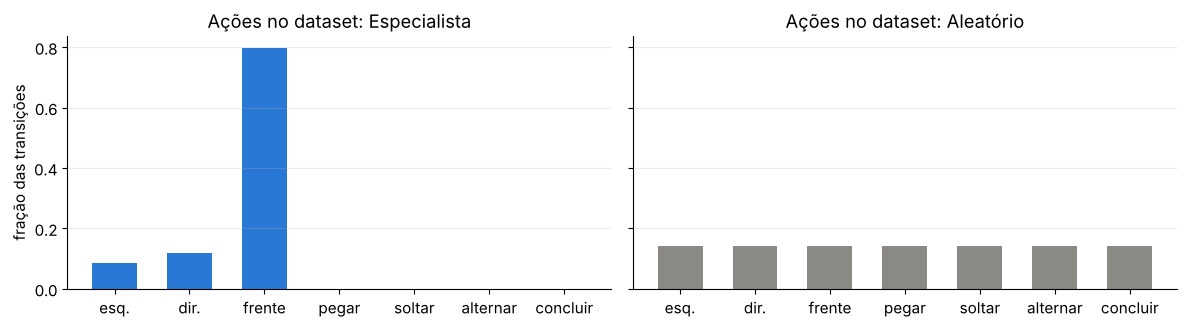

In [2]:
COR = {"BC": "#2a78d6", "DQN offline": "#eb6834", "CQL": "#1baf7a", "IQL": "#eda100"}
CINZA, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11, "lines.linewidth": 2})

def resumo(ds):
    rets = np.array([ep.rewards.sum() for ep in ds.iterate_episodes()])
    sucesso = np.array([ep.terminations[-1] for ep in ds.iterate_episodes()])
    acoes = np.concatenate([ep.actions for ep in ds.iterate_episodes()])
    return rets, sucesso, np.bincount(acoes, minlength=7)

ret_e, suc_e, ac_e = resumo(ds_expert)
ret_r, suc_r, ac_r = resumo(ds_random)
print(f"especialista: retorno médio {ret_e.mean():.3f} | sucesso {suc_e.mean():.1%}")
print(f"aleatório   : retorno médio {ret_r.mean():.3f} | sucesso {suc_r.mean():.1%} "
      f"({suc_r.sum()} episódios de sucesso em {len(suc_r)})")

nomes_acoes = ["esq.", "dir.", "frente", "pegar", "soltar", "alternar", "concluir"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, ac, titulo, cor in [(axs[0], ac_e, "Especialista", COR["BC"]), (axs[1], ac_r, "Aleatório", CINZA)]:
    ax.bar(nomes_acoes, ac / ac.sum(), color=cor, width=0.6)
    ax.set_title(f"Ações no dataset: {titulo}"); ax.grid(axis="x", visible=False)
axs[0].set_ylabel("fração das transições")
plt.tight_layout(); plt.show()

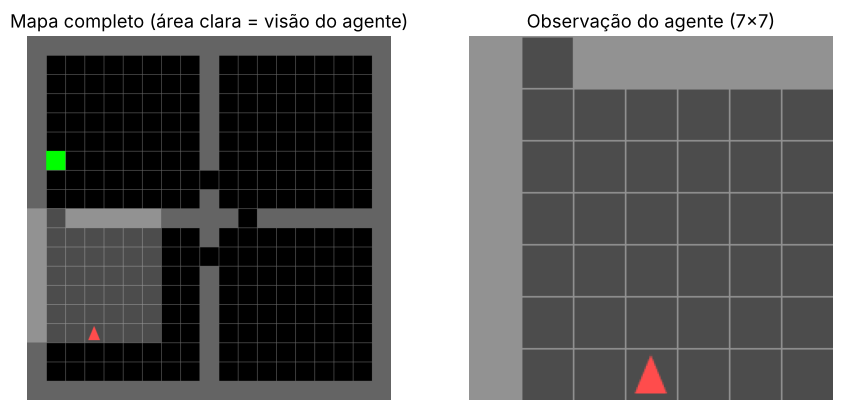

In [3]:
# Como é um episódio: mapa completo (o que o especialista conhece) × visão 7x7 (o que o agente observa)
env = gym.make("MiniGrid-FourRooms-v0", render_mode="rgb_array")
obs, _ = env.reset(seed=3)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
axs[0].imshow(env.render()); axs[0].set_title("Mapa completo (área clara = visão do agente)")
axs[1].imshow(env.unwrapped.get_pov_render(tile_size=32)); axs[1].set_title("Observação do agente (7×7)")
for ax in axs: ax.axis("off"); ax.grid(False)
plt.tight_layout(); plt.show()

**O que observar:**
- O especialista **nunca** usa as ações 3 a 6, e anda para frente em quase 80% dos passos. Para essas ações, e para "girar" em corredores onde ele sempre seguiu reto, o dataset não traz nenhuma evidência.
- A política aleatória raramente chega ao objetivo, mas em 1 milhão de passos acumula centenas de sucessos e cobre todas as ações em todo tipo de estado.

## 2. Os quatro algoritmos

Todos usam a mesma entrada (one-hot de objeto, cor e estado em cada célula da visão 7×7, mais a direção: 984 dimensões),
a mesma MLP (984 → 256 → 256 → saída), Adam, *batch* de 256 e o mesmo número de passos de gradiente.

**BC:** $\min_\pi \; \mathbb{E}_{(s,a)\sim\mathcal{D}}[-\log \pi(a|s)]$

**DQN offline (Double DQN):** $\big(Q(s,a) - [r + \gamma\, Q_{\bar\theta}(s', \arg\max_{a'} Q(s',a'))]\big)^2$. O $\max$ consulta ações que podem não existir nos dados.

**CQL:** a perda do DQN mais $\alpha\,\big(\log\sum_a e^{Q(s,a)} - Q(s,a_{\mathcal{D}})\big)$, que empurra para baixo todas as ações e para cima a ação vista. Usamos $\alpha = 0{,}5$.

**IQL** (Kostrikov et al., 2021) troca o $\max$ por algo que só usa ações **do dataset**:
1. $V(s)$ aprende o **expectil** $\tau$ de $Q(s, a_{\mathcal{D}})$: $\;\mathcal{L}_V = \mathbb{E}\big[\,|\tau - \mathbb{1}(u<0)|\, u^2\big]$, com $u = Q(s,a) - V(s)$. Com $\tau = 0{,}5$ seria a média (SARSA); com $\tau \to 1$ aproxima o máximo **entre as ações que aparecem nos dados**.
2. $Q(s,a)$ aprende por TD com $V(s')$: $\;\big(Q(s,a) - [r + \gamma V(s')]\big)^2$. Não há $\max$ sobre ações.
3. A política é extraída por **regressão ponderada pela vantagem**: $\;\max_\pi \mathbb{E}\big[e^{\beta (Q(s,a) - V(s))} \log \pi(a|s)\big]$. É um BC que dá mais peso às ações melhores que a média. Usamos $\tau=0{,}7$ e $\beta=3$.

A célula abaixo grava o código em `orl_minigrid.py` para que os experimentos possam rodar em paralelo, um processo por núcleo.

In [4]:
%%writefile orl_minigrid.py
"""Offline RL em MiniGrid FourRooms: BC, DQN offline, CQL e IQL (ações discretas)."""
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
torch.set_num_threads(1)
import gymnasium as gym, minigrid  # noqa: F401  (registra os ambientes MiniGrid)

N_ACOES = 7
N_OBJ, N_COR, N_EST = 11, 6, 3
DIM_ENTRADA = 7 * 7 * (N_OBJ + N_COR + N_EST) + 4


# ----------------------------------------------------------------------------- dados
def carregar_transicoes(dataset):
    """Converte um MinariDataset em arrays compactos (imagem em uint8)."""
    img, dir_, a, r, img2, dir2, d, retornos, tamanhos = [], [], [], [], [], [], [], [], []
    for ep in dataset.iterate_episodes():
        o = ep.observations
        img.append(o["image"][:-1]); img2.append(o["image"][1:])
        dir_.append(o["direction"][:-1]); dir2.append(o["direction"][1:])
        a.append(ep.actions); r.append(ep.rewards)
        d.append(ep.terminations.astype(np.float32))  # truncation não é terminal
        retornos.append(ep.rewards.sum()); tamanhos.append(len(ep.actions))
    cat = np.concatenate
    dados = dict(img=cat(img), dir=cat(dir_).astype(np.int64), a=cat(a).astype(np.int64),
                 r=cat(r).astype(np.float32), img2=cat(img2), dir2=cat(dir2).astype(np.int64),
                 d=cat(d))
    return dados, np.array(retornos), np.array(tamanhos)


def juntar(*conjuntos):
    return {k: np.concatenate([c[k] for c in conjuntos]) for k in conjuntos[0]}


def codificar(img, direcao):
    """one-hot de (objeto, cor, estado) em cada célula da visão 7x7 + direção."""
    img = torch.as_tensor(img, dtype=torch.long)
    partes = [F.one_hot(img[..., 0].clamp(max=N_OBJ - 1), N_OBJ),
              F.one_hot(img[..., 1].clamp(max=N_COR - 1), N_COR),
              F.one_hot(img[..., 2].clamp(max=N_EST - 1), N_EST)]
    x = torch.cat(partes, -1).flatten(1).float()
    return torch.cat([x, F.one_hot(torch.as_tensor(direcao, dtype=torch.long), 4).float()], 1)


class Amostrador:
    def __init__(self, dados, seed=0):
        self.dados, self.n = dados, len(dados["a"])
        self.rng = np.random.default_rng(seed)

    def __call__(self, bs=256):
        i = self.rng.integers(self.n, size=bs)
        D = self.dados
        return (codificar(D["img"][i], D["dir"][i]), torch.as_tensor(D["a"][i]),
                torch.as_tensor(D["r"][i]), codificar(D["img2"][i], D["dir2"][i]),
                torch.as_tensor(D["d"][i]))


def mlp(saida=N_ACOES, h=256):
    return nn.Sequential(nn.Linear(DIM_ENTRADA, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(),
                         nn.Linear(h, saida))


def atualizar_alvo(rede, alvo, tau=0.005):
    with torch.no_grad():
        for p, pa in zip(rede.parameters(), alvo.parameters()):
            pa.mul_(1 - tau).add_(tau * p)


# ----------------------------------------------------------------------------- algoritmos
def treinar_bc(dados, passos=20000, bs=256, seed=0, lr=1e-3, **_):
    torch.manual_seed(seed); amostra = Amostrador(dados, seed)
    pi = mlp(); opt = torch.optim.Adam(pi.parameters(), lr)
    for _ in range(passos):
        s, a, *_ = amostra(bs)
        perda = F.cross_entropy(pi(s), a)
        opt.zero_grad(); perda.backward(); opt.step()
    return pi, {}


def treinar_q(dados, alpha=0.0, passos=20000, bs=256, gamma=0.99, seed=0, lr=3e-4,
              log_cada=1000, s_monitor=None, **_):
    """alpha = 0 -> DQN offline (Double DQN); alpha > 0 -> CQL(H) discreto."""
    torch.manual_seed(seed); amostra = Amostrador(dados, seed)
    q, q_alvo = mlp(), mlp(); q_alvo.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr)
    hist = []
    for t in range(1, passos + 1):
        s, a, r, s2, d = amostra(bs)
        with torch.no_grad():
            a2 = q(s2).argmax(1, keepdim=True)
            y = r + gamma * (1 - d) * q_alvo(s2).gather(1, a2).squeeze(1)
        q_s = q(s); q_sa = q_s.gather(1, a[:, None]).squeeze(1)
        perda = F.mse_loss(q_sa, y)
        if alpha > 0:
            perda = perda + alpha * (torch.logsumexp(q_s, 1) - q_sa).mean()
        opt.zero_grad(); perda.backward(); opt.step(); atualizar_alvo(q, q_alvo)
        if s_monitor is not None and t % log_cada == 0:
            with torch.no_grad():
                qm = q(s_monitor)
                hist.append((t, qm.max(1).values.mean().item(), qm[:, 3:].max(1).values.mean().item()))
    return q, {"hist": np.array(hist)}


def treinar_iql(dados, passos=20000, bs=256, gamma=0.99, seed=0, lr=3e-4, tau_expectile=0.7,
                beta=10.0, log_cada=1000, s_monitor=None, **_):
    """IQL: V por regressão de expectil sobre Q(s, a_dados); Q por TD com V(s');
    política extraída por regressão ponderada pela vantagem (AWR). Nunca consulta ações OOD."""
    torch.manual_seed(seed); amostra = Amostrador(dados, seed)
    q1, q2, v, pi = mlp(), mlp(), mlp(1), mlp()
    q1a, q2a = mlp(), mlp(); q1a.load_state_dict(q1.state_dict()); q2a.load_state_dict(q2.state_dict())
    opt_q = torch.optim.Adam(list(q1.parameters()) + list(q2.parameters()), lr)
    opt_v = torch.optim.Adam(v.parameters(), lr)
    opt_pi = torch.optim.Adam(pi.parameters(), lr)
    hist = []
    for t in range(1, passos + 1):
        s, a, r, s2, d = amostra(bs)
        # 1) V(s) ~ expectil tau de Q_alvo(s, a) com a vindo dos DADOS
        with torch.no_grad():
            q_alvo = torch.min(q1a(s), q2a(s)).gather(1, a[:, None]).squeeze(1)
        u = q_alvo - v(s).squeeze(1)
        peso = torch.abs(tau_expectile - (u < 0).float())
        perda_v = (peso * u ** 2).mean()
        opt_v.zero_grad(); perda_v.backward(); opt_v.step()
        # 2) Q(s, a) <- r + gamma V(s')   (sem max sobre ações!)
        with torch.no_grad():
            y = r + gamma * (1 - d) * v(s2).squeeze(1)
        perda_q = (F.mse_loss(q1(s).gather(1, a[:, None]).squeeze(1), y) +
                   F.mse_loss(q2(s).gather(1, a[:, None]).squeeze(1), y))
        opt_q.zero_grad(); perda_q.backward(); opt_q.step()
        atualizar_alvo(q1, q1a); atualizar_alvo(q2, q2a)
        # 3) política: BC ponderado por exp(beta * vantagem)
        with torch.no_grad():
            adv = q_alvo - v(s).squeeze(1)
            w = torch.exp(beta * adv).clamp(max=100.0)
        perda_pi = (w * F.cross_entropy(pi(s), a, reduction="none")).mean()
        opt_pi.zero_grad(); perda_pi.backward(); opt_pi.step()
        if s_monitor is not None and t % log_cada == 0:
            with torch.no_grad():
                qm = torch.min(q1(s_monitor), q2(s_monitor))
                hist.append((t, qm.max(1).values.mean().item(), qm[:, 3:].max(1).values.mean().item()))
    return pi, {"hist": np.array(hist)}


# ----------------------------------------------------------------------------- avaliação
def avaliar(rede, n=100, seed=10_000, env_id="MiniGrid-FourRooms-v0"):
    """Avaliação online (só possível porque temos o simulador). Política gulosa."""
    env = gym.make(env_id); rets, suc = [], []
    for k in range(n):
        o, _ = env.reset(seed=seed + k); done, R = False, 0.0
        while not done:
            with torch.no_grad():
                a = int(rede(codificar(o["image"][None], [o["direction"]])).argmax())
            o, r, term, trunc, _ = env.step(a); R += r; done = term or trunc
        rets.append(R); suc.append(float(term))
    return np.array(rets), np.array(suc)


def avaliar_aleatoria(n=100, seed=10_000, env_id="MiniGrid-FourRooms-v0"):
    env = gym.make(env_id); env.action_space.seed(0); rets = []
    for k in range(n):
        env.reset(seed=seed + k); done, R = False, 0.0
        while not done:
            _, r, term, trunc, _ = env.step(env.action_space.sample()); R += r; done = term or trunc
        rets.append(R)
    return np.array(rets)


# ----------------------------------------------------------------------------- experimentos
IDS = {"expert": "D4RL/minigrid/fourrooms-v0", "random": "D4RL/minigrid/fourrooms-random-v0"}
_CACHE = {}


def obter_dados(nome):
    """'expert', 'random' ou 'misto' (= expert + random). Carregado uma vez por processo."""
    import minari
    if nome not in _CACHE:
        if nome == "misto":
            _CACHE[nome] = juntar(obter_dados("expert"), obter_dados("random"))
        else:
            _CACHE[nome] = carregar_transicoes(minari.load_dataset(IDS[nome], download=True))[0]
    return _CACHE[nome]


ALGORITMOS = {
    "BC":          (treinar_bc,  {}),
    "DQN offline": (treinar_q,   {"alpha": 0.0}),
    "CQL":         (treinar_q,   {"alpha": 0.5}),
    "IQL":         (treinar_iql, {"tau_expectile": 0.7, "beta": 3.0}),
}


def rodar_job(args):
    """Treina um algoritmo em um dataset com uma semente e avalia a política."""
    import time
    nome_ds, algo, seed, passos = args
    dados = obter_dados(nome_ds)
    s_monitor = codificar(obter_dados("expert")["img"][:1000], obter_dados("expert")["dir"][:1000])
    fn, kw = ALGORITMOS[algo]
    t0 = time.time()
    rede, info = fn(dados, passos=passos, seed=seed, s_monitor=s_monitor, log_cada=passos // 15, **kw)
    rets, suc = avaliar(rede)
    return dict(dataset=nome_ds, algo=algo, seed=seed, retorno=float(rets.mean()), sucesso=float(suc.mean()),
                hist=info.get("hist", np.zeros((0, 3))).tolist(), segundos=time.time() - t0)

Overwriting orl_minigrid.py


## 3. Experimentos

> Se o arquivo `resultados_offline_rl.json` já existir, a célula de treino só o recarrega. Para treinar do zero, apague o arquivo.

3 cenários (especialista, aleatório, misto) × 4 algoritmos × 2 sementes = 24 treinos de **15.000 passos de gradiente** cada.
Cada política é avaliada em **100 episódios** com sementes que não aparecem no treino, no próprio simulador.
Num problema real, essa avaliação seria feita com *Off-Policy Evaluation*.

Durante o treino guardamos, sobre 1.000 estados do dataset especialista:
- a média de $\max_a Q(s,a)$. O maior retorno possível é menor que 1, então valores acima de 1 indicam **superestimação**;
- a média de $\max_{a \in \{3..6\}} Q(s,a)$, o valor das ações que o especialista **nunca** usou.

In [5]:
from concurrent.futures import ProcessPoolExecutor
import orl_minigrid as orl

PASSOS, SEMENTES = 15_000, [0, 1]
CENARIOS, METODOS = ["expert", "random", "misto"], list(orl.ALGORITMOS)
jobs = [(d, m, s, PASSOS) for d in CENARIOS for m in METODOS for s in SEMENTES]
jobs.sort(key=lambda j: j[1] != "IQL")          # os mais lentos primeiro

ARQ = "resultados_offline_rl.json"
if os.path.exists(ARQ):                          # reaproveita uma execução anterior completa
    resultados = json.load(open(ARQ))
else:
    t0, resultados = time.time(), []
    with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
        for r in ex.map(orl.rodar_job, jobs):
            resultados.append(r)
            print(f"[{(time.time()-t0)/60:5.1f} min] {r['dataset']:6s} {r['algo']:12s} seed {r['seed']}: "
                  f"sucesso {r['sucesso']:.0%}  retorno {r['retorno']:.3f}", flush=True)
    json.dump(resultados, open(ARQ, "w"))
print(len(resultados), "treinos concluídos")

24 treinos concluídos


## 4. Resultados

In [6]:
import pandas as pd
df = pd.DataFrame(resultados)
aleatoria = orl.avaliar_aleatoria(n=100).mean()
especialista = ret_e.mean()
df["score_normalizado"] = 100 * (df.retorno - aleatoria) / (especialista - aleatoria)

tab = (df.groupby(["dataset", "algo"])[["sucesso", "retorno", "score_normalizado"]]
         .agg(["mean", "std"]).reindex(CENARIOS, level=0))
tab = tab.reindex(pd.MultiIndex.from_product([CENARIOS, METODOS]))
fmt = lambda m, s, p: f"{(round(m) + 0 if p == '.0f' else m):{p}} ± {s:{p}}"
tabela = pd.DataFrame({
    "sucesso (%)": [fmt(100*a, 100*b, ".0f") for a, b in tab["sucesso"].values],
    "retorno":     [fmt(a, b, ".3f") for a, b in tab["retorno"].values],
    "score normalizado": [fmt(a, b, ".0f") for a, b in tab["score_normalizado"].values],
}, index=tab.index)
print(f"Referências: política aleatória = {aleatoria:.3f} (score 0) | especialista = {especialista:.3f} (score 100)\n")
tabela

Referências: política aleatória = 0.002 (score 0) | especialista = 0.848 (score 100)



sucesso (%)        retorno score normalizado
expert BC               55 ± 2  0.426 ± 0.012            50 ± 1
       DQN offline       0 ± 0  0.000 ± 0.000             0 ± 0
       CQL              59 ± 4  0.451 ± 0.010            53 ± 1
       IQL             53 ± 18  0.410 ± 0.112           48 ± 13
random BC                0 ± 0  0.000 ± 0.000             0 ± 0
       DQN offline       0 ± 0  0.000 ± 0.000             0 ± 0
       CQL               0 ± 0  0.000 ± 0.000             0 ± 0
       IQL               0 ± 0  0.000 ± 0.000             0 ± 0
misto  BC                0 ± 0  0.000 ± 0.000             0 ± 0
       DQN offline      8 ± 11  0.075 ± 0.106            9 ± 13
       CQL              12 ± 1  0.108 ± 0.006            13 ± 1
       IQL              20 ± 4  0.180 ± 0.030            21 ± 4

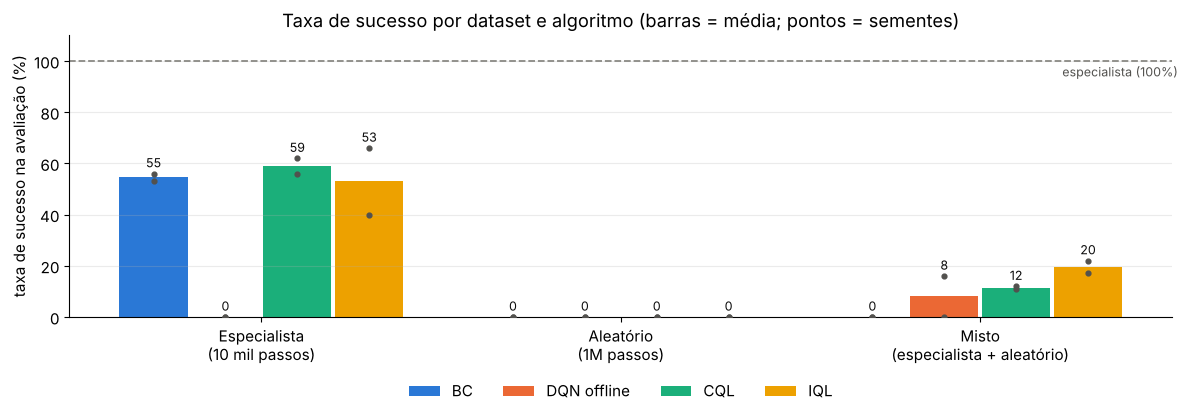

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.4))
larg = 0.19
for j, m in enumerate(METODOS):
    medias = [df[(df.dataset == d) & (df.algo == m)].sucesso.mean() * 100 for d in CENARIOS]
    xs = np.arange(len(CENARIOS)) + (j - 1.5) * (larg + 0.01)
    ax.bar(xs, medias, width=larg, color=COR[m], label=m)
    for d_i, (x, v) in enumerate(zip(xs, medias)):
        pts = df[(df.dataset == CENARIOS[d_i]) & (df.algo == m)].sucesso * 100
        ax.scatter([x] * len(pts), pts, s=12, color=TINTA, zorder=3)
        ax.text(x, max(v, pts.max()) + 2.5, f"{v:.0f}", ha="center", fontsize=9, color="#0b0b0b")
ax.axhline(suc_e.mean() * 100, color=CINZA, ls="--", lw=1.3)
ax.text(2.55, suc_e.mean() * 100 - 6, "especialista (100%)", ha="right", color=TINTA, fontsize=9)
ax.set_xticks(range(len(CENARIOS)), ["Especialista\n(10 mil passos)", "Aleatório\n(1M passos)", "Misto\n(especialista + aleatório)"])
ax.set_ylabel("taxa de sucesso na avaliação (%)"); ax.set_ylim(0, 110); ax.grid(axis="x", visible=False)
ax.set_title("Taxa de sucesso por dataset e algoritmo (barras = média; pontos = sementes)")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.show()

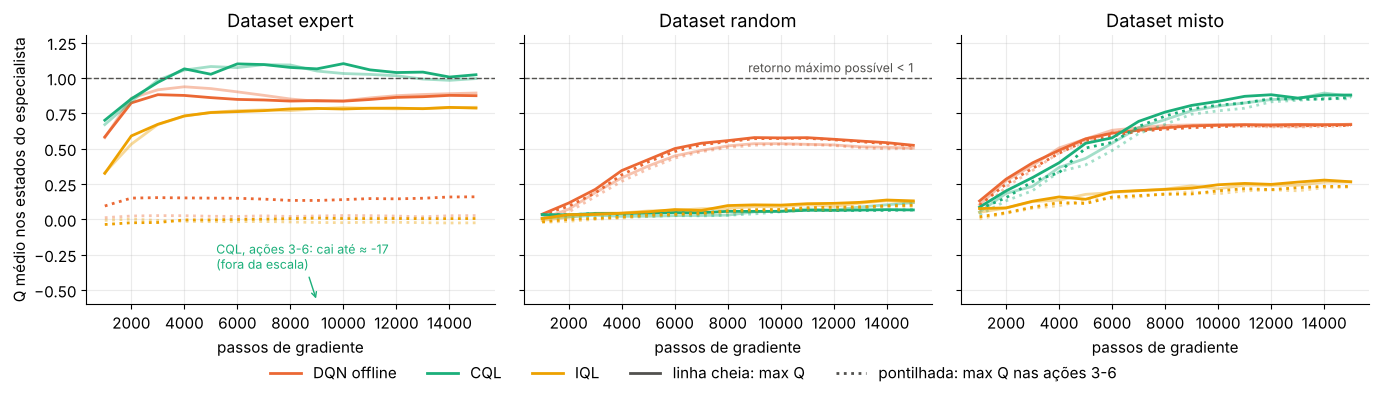

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, d in zip(axs, CENARIOS):
    for m in ["DQN offline", "CQL", "IQL"]:
        for k, h in enumerate(df[(df.dataset == d) & (df.algo == m)]["hist"]):
            h = np.array(h)
            ax.plot(h[:, 0], h[:, 1], color=COR[m], alpha=1 if k == 0 else 0.4, label=m if k == 0 else None)
            ax.plot(h[:, 0], h[:, 2], color=COR[m], ls=":", alpha=1 if k == 0 else 0.4)
    ax.axhline(1.0, color=TINTA, ls="--", lw=1)
    ax.set_ylim(-0.6, 1.3)
    ax.set_title(f"Dataset {d}"); ax.set_xlabel("passos de gradiente")
axs[0].annotate("CQL, ações 3-6: cai até ≈ -17\n(fora da escala)", xy=(9000, -0.58), xytext=(5200, -0.35),
                color=COR["CQL"], fontsize=9, arrowprops=dict(arrowstyle="->", color=COR["CQL"]))
axs[0].set_ylabel("Q médio nos estados do especialista")
axs[1].text(15000, 1.04, "retorno máximo possível < 1", color=TINTA, fontsize=9, ha="right")
from matplotlib.lines import Line2D
leg = [Line2D([], [], color=COR[m], label=m) for m in ["DQN offline", "CQL", "IQL"]] + \
      [Line2D([], [], color=TINTA, label="linha cheia: max Q"), Line2D([], [], color=TINTA, ls=":", label="pontilhada: max Q nas ações 3-6")]
fig.legend(handles=leg, ncol=5, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.show()

## 5. O que os resultados mostram

| Taxa de sucesso (média de 2 sementes) | BC | DQN offline | CQL | IQL |
|---|---|---|---|---|
| **Especialista** | 55% | **0%** | **59%** | 53% |
| **Aleatório** | 0% | 0% | 0% | 0% |
| **Misto** | **0%** | 8% | 12% | **20%** |

### Dataset especialista: o erro de extrapolação em ação
- **BC, CQL e IQL empatam**, considerando a variação entre sementes (o IQL variou de 40% a 66%). Nenhum chega perto dos 100% do especialista: ele conhecia o mapa inteiro, e o agente vê só uma janela 7×7. É um problema parcialmente observável, e nenhuma política sem memória iguala o especialista. Isso limita os quatro métodos igualmente.
- **O DQN offline colapsa para 0%.** Ele não escolhe as ações 3 a 6 (veja a linha pontilhada laranja, bem abaixo do máximo): ele **fica girando no lugar**. Nos corredores o especialista sempre andou para frente, então "girar" ali é uma ação fora da distribuição *naquele estado*. O valor dela é extrapolado, empata com o de "frente", e o agente entra em loop. **A distribuição que importa é a de pares (estado, ação)**, não a de ações isoladas. Repare que o Q do DQN nem chega a explodir: o erro de extrapolação destrói a política mesmo com valores de aparência razoável. (O CQL é que fica um pouco **acima de 1**: o pessimismo dele cai sobre as ações sem suporte, não sobre todas.)
- O **CQL** joga o valor das ações sem suporte para cerca de -17. O IQL nunca as consulta. Os dois se comportam como "BC com valor".

### Dataset aleatório: cobertura não basta
Nenhum método aprendeu, nem os de valor. O diagnóstico (feito fora deste notebook) mostra que as políticas treinadas aqui **nunca escolhem andar para frente**: ou giram, ou escolhem uma ação sem efeito. As causas se somam:
- **Recompensa muito esparsa:** apenas 294 episódios de sucesso em 1 milhão de passos, quase todos de episódios em que o objetivo nasceu ao lado do agente.
- **Action gap minúsculo:** com γ = 0,99, longe do objetivo a diferença de valor entre "frente" e "girar" é da ordem de 1% de V, menor que o ruído da aproximação. As curvas de Q ainda estavam subindo ao fim do treino.
- **Observação parcial:** a mesma visão 7×7 aparece em lugares com ações ótimas diferentes.

A promessa do Offline RL de "superar os dados" exige que os dados contenham **sinal suficiente** sobre o que funciona, não só cobertura.

### Dataset misto: onde o Offline RL faz diferença
- **O BC cai de 55% para 0%.** Com 99% de transições aleatórias, imitar "a média" é imitar o aleatório. Os ~10 mil passos de especialista se perdem.
- **Os três métodos de valor recuperam parte do desempenho**, porque usam a recompensa para dar peso ao comportamento que leva ao objetivo. O **IQL** foi o melhor (20%), seguido de CQL (12%) e DQN offline (8%, com uma semente em 0%).
- Ainda falta muito para os 55% obtidos com o especialista puro. **Filtrar os bons dados** (por exemplo, BC só nos episódios de maior retorno, o "%BC") seria um baseline fortíssimo aqui e deveria ser testado.
- Num teste rápido (1 semente), o CQL com **γ = 0,9** subiu de 12% para 27% no misto, o que confirma o papel do *action gap*. γ é um hiperparâmetro a ajustar, não uma constante.

## 6. Lições práticas
1. **Rode BC primeiro, e também BC filtrado pelos melhores episódios.** Com dados de especialista, o BC já empata com CQL e IQL.
2. **Nunca use Q-learning ingênuo offline.** O DQN offline foi o único a zerar no especialista. Use pessimismo (CQL), extração implícita (IQL) ou restrição à política dos dados (TD3+BC, BCQ).
3. **Offline RL brilha quando há dados bons diluídos em dados ruins** (cenário misto). É aí que imitação simples falha e a recompensa faz diferença.
4. **Cobertura sem sinal não resolve.** Dados aleatórios com recompensa esparsa podem ser inúteis, qualquer que seja o algoritmo.
5. **IQL** foi o mais robusto entre os cenários, mas é cerca de 3× mais caro por passo. **CQL** é sensível a α e γ.
6. **Hiperparâmetros** (α, τ, β, γ) foram fixados sem busca. Num problema real, a seleção exige *Off-Policy Evaluation* (FQE, importance sampling, doubly robust), pois não há simulador.
7. **Observação parcial** limita todos os métodos aqui. Uma política recorrente (LSTM/GRU) ou *frame stacking* é o próximo passo natural.

**Para ir além:** mais passos de treino e mais sementes; varrer γ e α; adicionar %BC; datasets de ações contínuas do Minari (`mujoco/halfcheetah/medium-v0`, com versões contínuas de CQL e IQL e TD3+BC); bibliotecas como **d3rlpy** e **CORL**.